In [ ]:
from google.colab import files
uploaded = files.upload()

Saving pl_applicants.csv to pl_applicants.csv
Saving pl_loans.csv to pl_loans.csv


In [ ]:
import pandas as pd

app = pd.read_csv('pl_applicants.csv')
loans = pd.read_csv('pl_loans.csv')

print(app.shape, loans.shape)
app.head()

(3020, 8) (3000, 14)


,applicant_id,age,employment_type,annual_income_inr,credit_score,city_tier,existing_loans,years_with_bank
0,1,39,Salaried,407468.0,704.0,Tier 1,1,8
1,2,25,self-employed,212459.0,711.0,Tier 1,2,2
2,3,26,Salaried,325967.0,596.0,Tier 3,0,14
3,4,41,Salaried,346485.0,668.0,Tier 2,0,8
4,5,42,Salaried,172081.0,NaN,Tier 2,1,1


In [ ]:
print(app.isnull().sum())
print("Duplicates:", app.duplicated().sum())

applicant_id           0
age                    0
employment_type        0
annual_income_inr     83
credit_score         138
city_tier              0
existing_loans         0
years_with_bank        0
dtype: int64
Duplicates: 20


In [ ]:
# 1. Remove the 20 duplicate rows
app = app.drop_duplicates()

# 2. Fix the casing in employment_type (e.g. "self-employed" vs "Self-employed")
app['employment_type'] = app['employment_type'].str.strip().str.title()

# 3. Fill missing income and credit score with the median
app['annual_income_inr'] = app['annual_income_inr'].fillna(app['annual_income_inr'].median())
app['credit_score'] = app['credit_score'].fillna(app['credit_score'].median())

# 4. Check the results
print("Rows now:", len(app))
print("Duplicates left:", app.duplicated().sum())
print("Missing left:", app.isnull().sum().sum())
print(app['employment_type'].value_counts())

Rows now: 3000
Duplicates left: 0
Missing left: 0
employment_type
Salaried          1781
Self-Employed      769
Business Owner     450
Name: count, dtype: int64


In [ ]:
# Join loans to the cleaned applicant table on applicant_id
df = loans.merge(app, on='applicant_id', how='left')

print("Shape:", df.shape)
print("Rows match loans table:", len(df) == len(loans))
print("Missing values per column:")
print(df.isnull().sum())

Shape: (3000, 21)
Rows match loans table: True
Missing values per column:
loan_id                 0
applicant_id            0
application_date        0
loan_product            0
loan_amount_inr         0
tenure_months           0
interest_rate_pct       0
emi_inr                 0
dti_ratio               0
approval_status         0
disbursed_date       1626
loan_status             0
max_dpd                 0
defaulted_flag          0
age                     0
employment_type         0
annual_income_inr       0
credit_score            0
city_tier               0
existing_loans          0
years_with_bank         0
dtype: int64


In [ ]:
# 1. Approval rate
print(df['approval_status'].value_counts())
print("Approval rate:", round((df['approval_status'] == 'Approved').mean() * 100, 1), "%")

# 2. Default analysis uses approved loans only
appr = df[df['approval_status'] == 'Approved'].copy()
print("\nApproved loans:", len(appr))
print("Overall default rate:", round(appr['defaulted_flag'].mean() * 100, 2), "%")

# 3. Default rate by employment type
print("\n--- By employment type ---")
print(appr.groupby('employment_type')['defaulted_flag'].agg(['count', 'mean']).round(4))

# 4. Default rate by credit score band
appr['credit_band'] = pd.cut(appr['credit_score'], bins=[0, 650, 720, 780, 900],
                             labels=['Below 650', '650-720', '720-780', 'Above 780'])
print("\n--- By credit score band ---")
print(appr.groupby('credit_band', observed=True)['defaulted_flag'].agg(['count', 'mean']).round(4))

# 5. Default rate by DTI band
appr['dti_band'] = pd.cut(appr['dti_ratio'], bins=[0, 0.4, 0.6, 100],
                          labels=['Below 0.4', '0.4-0.6', 'Above 0.6'])
print("\n--- By DTI band ---")
print(appr.groupby('dti_band', observed=True)['defaulted_flag'].agg(['count', 'mean']).round(4))

approval_status
Rejected    1626
Approved    1374
Name: count, dtype: int64
Approval rate: 45.8 %

Approved loans: 1374
Overall default rate: 9.83 %

--- By employment type ---
                 count    mean
employment_type               
Business Owner     204  0.1422
Salaried           827  0.0798
Self-Employed      343  0.1166

--- By credit score band ---
             count    mean
credit_band               
Below 650       64  0.1406
650-720        407  0.1646
720-780        608  0.0773
Above 780      295  0.0407

--- By DTI band ---
           count    mean
dti_band                
Below 0.4    353  0.0482
0.4-0.6      312  0.0929
Above 0.6    709  0.1255


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving pl_applicants.csv to pl_applicants.csv
Saving pl_loans.csv to pl_loans.csv


In [ ]:
import pandas as pd

# 1. Load
app = pd.read_csv('pl_applicants.csv')
loans = pd.read_csv('pl_loans.csv')
print("Loaded:", app.shape, loans.shape)

# 2. Clean applicants
app = app.drop_duplicates()
app['employment_type'] = app['employment_type'].str.strip().str.title()
app['annual_income_inr'] = app['annual_income_inr'].fillna(app['annual_income_inr'].median())
app['credit_score'] = app['credit_score'].fillna(app['credit_score'].median())
print("Cleaned applicants:", len(app), "| duplicates:", app.duplicated().sum(), "| missing:", app.isnull().sum().sum())
print(app['employment_type'].value_counts())

# 3. Join loans to cleaned applicants
df = loans.merge(app, on='applicant_id', how='left')
print("Joined shape:", df.shape)

Loaded: (3020, 8) (3000, 14)
Cleaned applicants: 3000 | duplicates: 0 | missing: 0
employment_type
Salaried          1781
Self-Employed      769
Business Owner     450
Name: count, dtype: int64
Joined shape: (3000, 21)


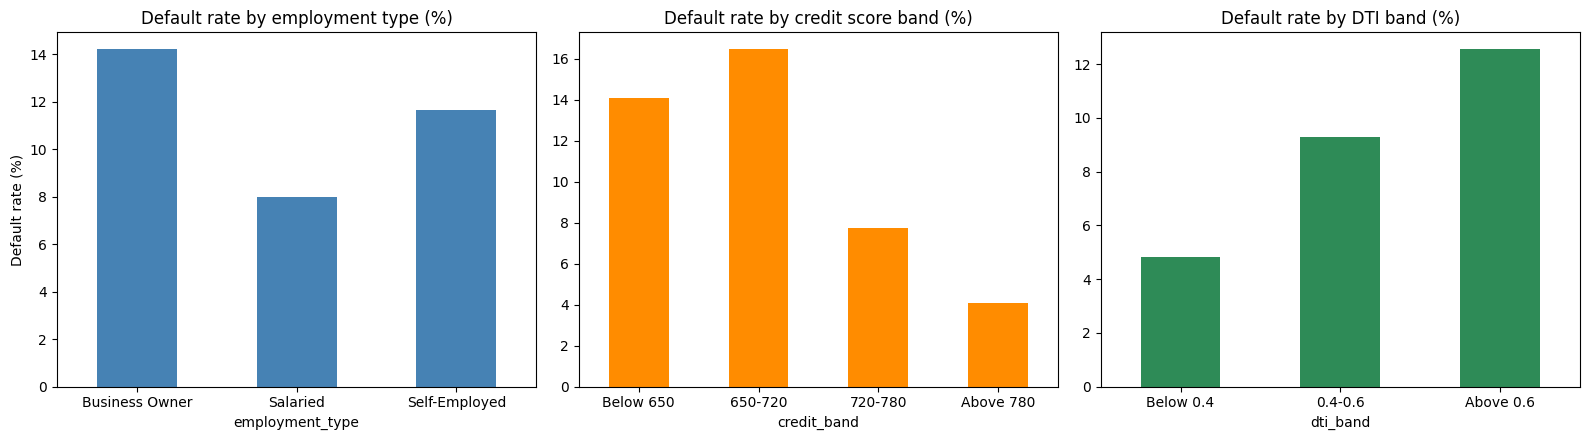

In [ ]:
import matplotlib.pyplot as plt

# Keep approved loans only, same as the default-rate analysis
appr = df[df['approval_status'] == 'Approved'].copy()
appr['credit_band'] = pd.cut(appr['credit_score'], bins=[0, 650, 720, 780, 900],
                             labels=['Below 650', '650-720', '720-780', 'Above 780'])
appr['dti_band'] = pd.cut(appr['dti_ratio'], bins=[0, 0.4, 0.6, 100],
                          labels=['Below 0.4', '0.4-0.6', 'Above 0.6'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Chart 1: default rate by employment type
emp = appr.groupby('employment_type')['defaulted_flag'].mean() * 100
emp.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Default rate by employment type (%)')
axes[0].set_ylabel('Default rate (%)')
axes[0].tick_params(axis='x', rotation=0)

# Chart 2: default rate by credit score band
cred = appr.groupby('credit_band', observed=True)['defaulted_flag'].mean() * 100
cred.plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Default rate by credit score band (%)')
axes[1].tick_params(axis='x', rotation=0)

# Chart 3: default rate by DTI band
dti = appr.groupby('dti_band', observed=True)['defaulted_flag'].mean() * 100
dti.plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title('Default rate by DTI band (%)')
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

Chart 1: Business owners default most (about 14%), self-employed next (about 12%), and salaried borrowers least (about 8%).

Chart 2: Loans in the 650–720 credit band default most (about 16%), while loans above 780 default least (about 4%). The below-650 group has only 64 loans, so treat it with caution.

Chart 3: Loans with a DTI above 0.6 default at about 13%, compared with about 5% for loans below 0.4.

Business owners default more than salaried borrowers: 14.2% compared with 8.0%.

Loans with a credit score of 650–720 default at 16.5%, compared with 4.1% for loans above 780.

Loans with a DTI above 0.6 default at 12.6%, compared with 4.8% for loans below 0.4.

The below-650 group has only 64 loans, so I treat that result with caution.


I recommend a stricter DTI cap of 0.5 for business owners and self-employed applicants, because they default more often and high-DTI loans default more.
All data in this notebook is synthetic, built for this practice project.